In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("aviation_aircraft_utilisation_2000.csv")

In [ ]:
print("Original shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Original shape: (2000, 8)

Missing values:
 Flight_ID             0
Aircraft_Type         3
Route                 0
Flight_Duration       3
Turnaround_Time       0
Route_Distance        0
Passenger_Capacity    0
Actual_Passengers     0
dtype: int64

Duplicate rows: 0


In [ ]:
numeric_cols = [
    "Flight_Duration", "Turnaround_Time", "Route_Distance",
    "Passenger_Capacity", "Actual_Passengers"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Treat blank aircraft types as missing
df["Aircraft_Type"] = df["Aircraft_Type"].replace(r"^\s*$", np.nan, regex=True)


In [ ]:
df.loc[df["Flight_Duration"] <= 0, "Flight_Duration"] = np.nan
df.loc[df["Turnaround_Time"] <= 0, "Turnaround_Time"] = np.nan
df.loc[df["Route_Distance"] <= 0, "Route_Distance"] = np.nan
df.loc[df["Passenger_Capacity"] <= 0, "Passenger_Capacity"] = np.nan
df.loc[df["Actual_Passengers"] < 0, "Actual_Passengers"] = np.nan

In [ ]:
df.loc[
    df["Actual_Passengers"] > df["Passenger_Capacity"],
    "Actual_Passengers"
] = np.nan


In [ ]:
df = df.drop_duplicates()


In [ ]:
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
df["Aircraft_Type"] = df["Aircraft_Type"].fillna(df["Aircraft_Type"].mode()[0])

In [ ]:
df["Passenger_Load_Factor"] = (
    df["Actual_Passengers"] / df["Passenger_Capacity"] * 100
)

# Block/operating time
df["Total_Operation_Time"] = (
    df["Flight_Duration"] + df["Turnaround_Time"] / 60
)

In [ ]:
df["Aircraft_Utilisation"] = (
    df["Flight_Duration"] / df["Total_Operation_Time"] * 100
)


In [ ]:
df["Occupancy_Category"] = pd.cut(
    df["Passenger_Load_Factor"],
    bins=[0, 60, 75, 90, 100],
    labels=["Low", "Moderate", "High", "Very High"],
    include_lowest=True
)

In [ ]:
print("\nDescriptive Statistics:")
print(df[numeric_cols + [
    "Passenger_Load_Factor", "Aircraft_Utilisation"
]].describe().round(2))

print("\nAircraft Type Summary:")
aircraft_summary = df.groupby("Aircraft_Type").agg(
    Flights=("Flight_ID", "count"),
    Avg_Distance_km=("Route_Distance", "mean"),
    Avg_Flight_Hours=("Flight_Duration", "mean"),
    Avg_Turnaround_min=("Turnaround_Time", "mean"),
    Avg_Load_Factor=("Passenger_Load_Factor", "mean"),
    Avg_Utilisation=("Aircraft_Utilisation", "mean")
).sort_values("Avg_Load_Factor", ascending=False)

print(aircraft_summary.round(2))

print("\nRoute Summary:")
route_summary = df.groupby("Route").agg(
    Flights=("Flight_ID", "count"),
    Avg_Load_Factor=("Passenger_Load_Factor", "mean"),
    Avg_Distance_km=("Route_Distance", "mean"),
    Avg_Utilisation=("Aircraft_Utilisation", "mean")
).sort_values("Avg_Load_Factor")

print(route_summary.round(2))


Descriptive Statistics:
       Flight_Duration  Turnaround_Time  Route_Distance  Passenger_Capacity  \
count          2000.00          2000.00         2000.00             2000.00   
mean              2.99            56.77         2361.23              182.33   
std               2.51            17.37         2167.89               64.58   
min               0.45            25.10          290.00               72.00   
25%               1.20            44.60          845.00              180.00   
50%               2.07            54.20         1315.00              189.00   
75%               4.28            65.32         3930.00              220.00   
max               8.98           109.80         7200.00              296.00   

       Actual_Passengers  Passenger_Load_Factor  Aircraft_Utilisation  
count            2000.00                2000.00               2000.00  
mean              118.05                  63.82                 68.12  
std                51.04                  11.98

In [ ]:
low_occupancy_routes = (
    df.groupby("Route")["Passenger_Load_Factor"]
      .mean()
      .sort_values()
)

print("\nRoutes with lowest average seat occupancy:")
print(low_occupancy_routes.head(10).round(2))


Routes with lowest average seat occupancy:
Route
Coimbatore-Chennai     55.91
Chennai-Bengaluru      57.61
Hyderabad-Chennai      58.23
Bengaluru-Hyderabad    58.87
Mumbai-Bengaluru       60.38
Delhi-Hyderabad        60.70
Mumbai-Kolkata         62.00
Delhi-Kolkata          62.26
Bengaluru-Mumbai       62.33
Chennai-Delhi          62.95
Name: Passenger_Load_Factor, dtype: float64


In [ ]:
combo_summary = df.groupby(
    ["Route", "Aircraft_Type"]
).agg(
    Flights=("Flight_ID", "count"),
    Avg_Load_Factor=("Passenger_Load_Factor", "mean"),
    Avg_Utilisation=("Aircraft_Utilisation", "mean"),
    Avg_Capacity=("Passenger_Capacity", "mean"),
    Avg_Passengers=("Actual_Passengers", "mean")
).reset_index()

inefficient = combo_summary[
    (combo_summary["Flights"] >= 5) &
    (combo_summary["Avg_Load_Factor"] < 65)
].sort_values("Avg_Load_Factor")

print("\nInefficient route-aircraft combinations:")
print(inefficient.head(15).round(2))


Inefficient route-aircraft combinations:
                  Route   Aircraft_Type  Flights  Avg_Load_Factor  \
30   Coimbatore-Chennai      ATR 72-600       23            52.54   
68    Hyderabad-Chennai      ATR 72-600       13            52.56   
57         Delhi-Mumbai      ATR 72-600       13            53.63   
33   Coimbatore-Chennai  Boeing 737-800       28            54.18   
19    Chennai-Bengaluru    Embraer E190       14            55.21   
71    Hyderabad-Chennai  Boeing 737-800       19            55.50   
72    Hyderabad-Chennai    Embraer E190       19            56.05   
24        Chennai-Delhi    Embraer E190       11            56.09   
31   Coimbatore-Chennai     Airbus A320       30            56.41   
15    Chennai-Bengaluru      ATR 72-600       22            56.44   
5   Bengaluru-Hyderabad      ATR 72-600       33            56.66   
17    Chennai-Bengaluru     Airbus A321       16            56.79   
73     Mumbai-Bengaluru      ATR 72-600       27            5

In [ ]:
features = [
    "Flight_Duration",
    "Turnaround_Time",
    "Route_Distance",
    "Passenger_Capacity"
]

X = df[features]
y = df["Passenger_Load_Factor"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n-----------------------------")
print("LINEAR REGRESSION RESULTS")
print("-----------------------------")
print("Intercept:", round(model.intercept_, 4))
print("\nCoefficients:")
for feature, coef in zip(features, model.coef_):
    print(f"{feature}: {coef:.4f}")

print("\nMAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))



-----------------------------
LINEAR REGRESSION RESULTS
-----------------------------
Intercept: 54.9145

Coefficients:
Flight_Duration: 0.1243
Turnaround_Time: 0.0253
Route_Distance: 0.0015
Passenger_Capacity: 0.0191

MAE : 8.3
RMSE: 10.83
R²  : 0.1813


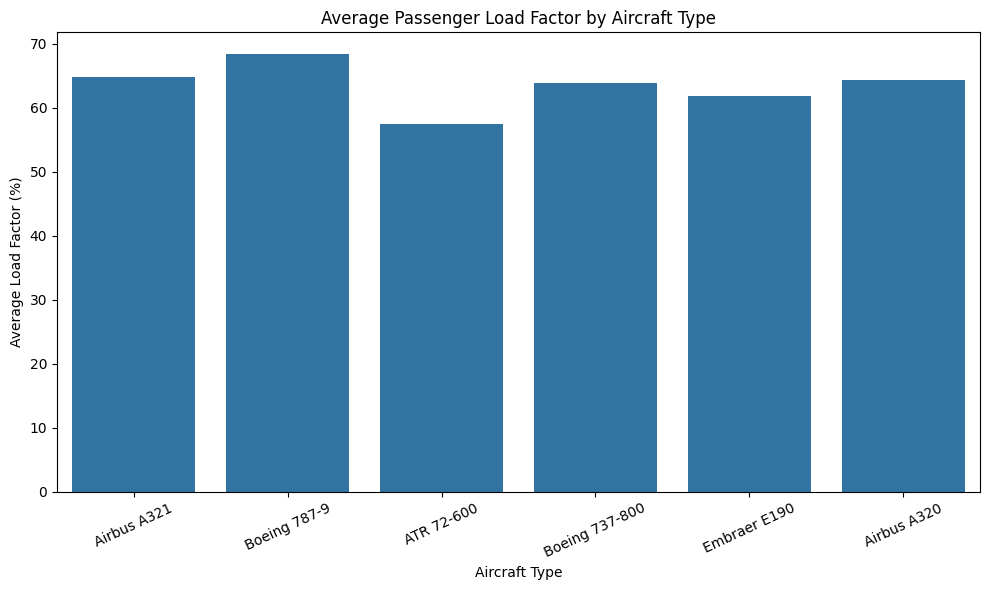

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="Aircraft_Type",
    y="Passenger_Load_Factor",
    estimator="mean",
    errorbar=None
)
plt.title("Average Passenger Load Factor by Aircraft Type")
plt.xlabel("Aircraft Type")
plt.ylabel("Average Load Factor (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

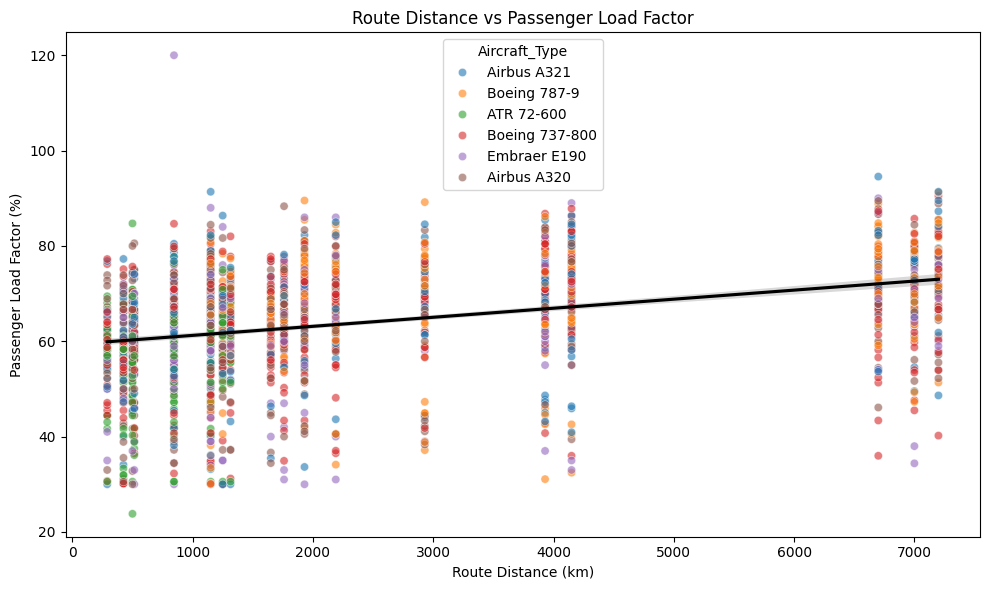

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Route_Distance",
    y="Passenger_Load_Factor",
    hue="Aircraft_Type",
    alpha=0.6
)
sns.regplot(
    data=df,
    x="Route_Distance",
    y="Passenger_Load_Factor",
    scatter=False,
    color="black"
)
plt.title("Route Distance vs Passenger Load Factor")
plt.xlabel("Route Distance (km)")
plt.ylabel("Passenger Load Factor (%)")
plt.tight_layout()
plt.show()


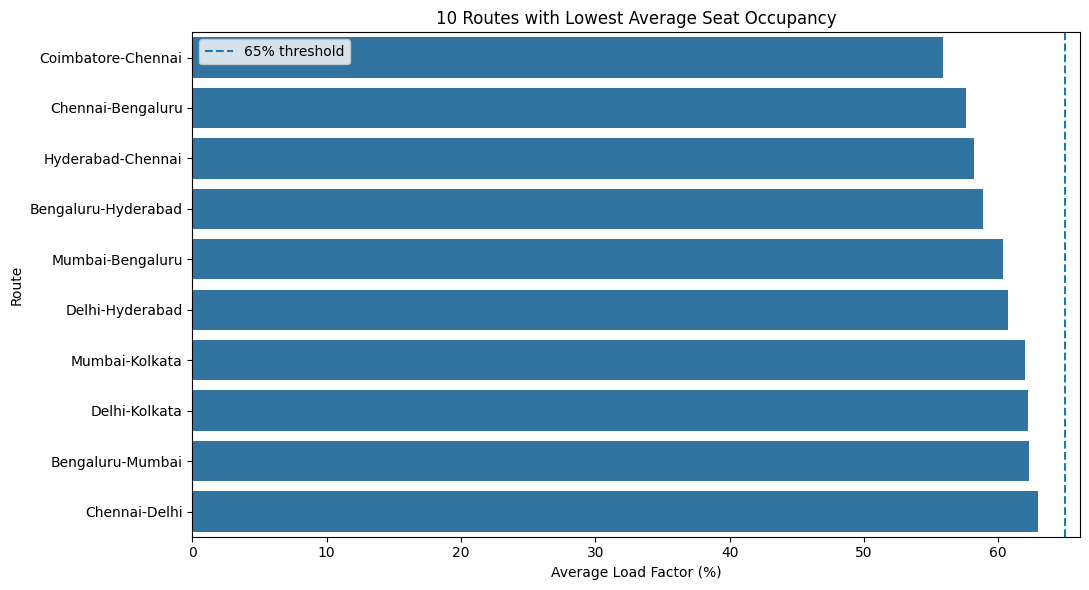

In [ ]:
route_plot = (
    df.groupby("Route")["Passenger_Load_Factor"]
      .mean()
      .sort_values()
      .head(10)
      .reset_index()
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=route_plot,
    x="Passenger_Load_Factor",
    y="Route"
)
plt.axvline(65, linestyle="--", label="65% threshold")
plt.title("10 Routes with Lowest Average Seat Occupancy")
plt.xlabel("Average Load Factor (%)")
plt.ylabel("Route")
plt.legend()
plt.tight_layout()
plt.show()

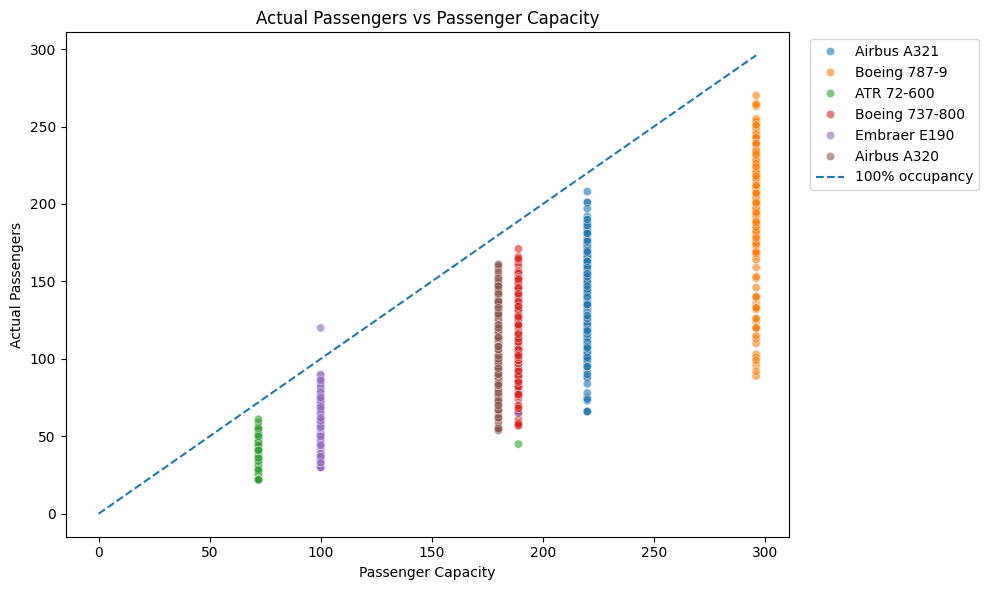

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Passenger_Capacity",
    y="Actual_Passengers",
    hue="Aircraft_Type",
    alpha=0.6
)
plt.plot(
    [0, df["Passenger_Capacity"].max()],
    [0, df["Passenger_Capacity"].max()],
    linestyle="--",
    label="100% occupancy"
)
plt.title("Actual Passengers vs Passenger Capacity")
plt.xlabel("Passenger Capacity")
plt.ylabel("Actual Passengers")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


KEY INSIGHTS
1. Aircraft types differ in average passenger load factor and utilisation.
2. Routes with low average load factor indicate weaker seat occupancy.
3. Route distance can be tested against load factor to assess whether longer routes perform better.
4. High-capacity aircraft on low-demand routes can create inefficient seat utilisation.
5. Turnaround time affects the aircraft operating cycle and therefore utilisation.
6. Route-aircraft combinations below the selected load-factor threshold should be reviewed.
7. Linear Regression provides a baseline estimate of passenger load factor from operational variables.



PRACTICAL ACTION PLAN
- Review routes with average load factor below 65%.
- Consider smaller aircraft on persistently low-demand routes.
- Increase frequency rather than aircraft size where demand is spread across flights.
- Reduce unnecessary turnaround time where operationally feasible.
- Use historical demand before assigning high-capacity aircraft.
- Reassess inefficient route-aircraft combinations monthly.
- Use the regression model as a baseline planning tool, not as the only fleet decision criterion.